In [1]:
import sys
from pathlib import Path
print(sys.executable)
assert Path(sys.prefix).resolve() == Path('/home/miakhlov/course-notebooks/.venv').resolve()

/home/miakhlov/course-notebooks/.venv/bin/python


# ЛР 1. Паспорт проекта и взаимодействие факторов

**Сущность:** Отделить исследовательский вопрос от инструмента и увидеть взаимодействие в плане 2×2.

**Данные:** factorial.csv: четыре искусственных отклика при кодированных A/B; единицы условные.

**Workflow:** Вопрос → факторы → модель с взаимодействием → эффекты → ограничение насыщенного плана.

Перед запуском прочитайте [guideline](../guides/lab01.md) и [теорию](../../Module_theory/Module%201_SDLC.md).

## 1. Прогноз

Запишите ожидаемое поведение и отрицательный контроль. Какое изменение входа должно изменить результат, а какое — сохранить?

In [2]:
from pathlib import Path
import sys, json, math, csv, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# WHY: relative discovery makes the notebook portable across machines.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Labs" / "chemistry.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Запустите notebook внутри репозитория курса")
sys.path.insert(0, str(ROOT / "Labs"))
DATA = ROOT / "Labs" / "datasets"
OUT = ROOT / "Labs" / "results" / "lab01"
OUT.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()


## 2. Разбор и исполнение

1. Прочитайте четыре строки и проверьте полный набор сочетаний ±1.
2. Постройте матрицу [1,A,B,A·B], решите систему и сравните коэффициенты с эффектами.
3. Покажите две линии отклика и объясните, почему непараллельность означает взаимодействие.

Ожидаемое: Численные эффекты 20/10/16; проверка покрытия четырёх комбинаций. Это тест арифметики, не экспериментальный эффект.

Коэффициенты: [50. 10.  5.  8.] Эффекты: [20. 10. 16.]


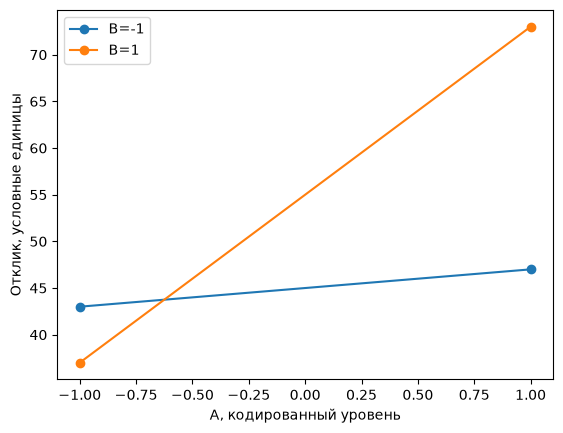

In [3]:
design = pd.read_csv(DATA / "factorial.csv")
x = np.column_stack([np.ones(len(design)), design.A, design.B, design.A*design.B])
beta = np.linalg.solve(x, design.y)
effects = 2*beta[1:]
print("Коэффициенты:", beta, "Эффекты:", effects)
assert np.allclose(beta, [50,10,5,8])
assert np.allclose(effects, [20,10,16])
assert len(set(zip(design.A, design.B))) == 4
for b, group in design.groupby("B"):
    group = group.sort_values("A")
    plt.plot(group.A, group.y, "o-", label=f"B={b}")
plt.xlabel("A, кодированный уровень"); plt.ylabel("Отклик, условные единицы")
plt.legend(); plt.savefig(OUT / "factorial.png", dpi=150); plt.show()
artifact = {"beta": beta.tolist(), "effects": effects.tolist(), "residual_df": 0}


## 3. Проверяемая запись запуска

Benchmark фиксирует этот запуск. Время включает расчёт и создание артефактов, но не установку среды; это не сравнительный рейтинг оборудования.

In [4]:
elapsed = time.perf_counter()-started
run_record = {"lab": 1, "calculation_wall_seconds": elapsed, "result": artifact}
(OUT/"benchmark.json").write_text(json.dumps(run_record,ensure_ascii=False,indent=2),encoding="utf-8")
print("Запуск сохранён:",OUT/"benchmark.json")


Запуск сохранён: /home/miakhlov/course-notebooks/Labs/results/lab01/benchmark.json


## 4. Самостоятельная тренировка

1. Восстановите пропущенный столбец AB и вычислите эффект A.
2. Предложите два повтора и объясните, какую неопределённость они оценят.
3. Перепишите цель своего проекта как величину, контроль и следующее решение.

[Ответы после попытки](../solutions/lab01.md). Вернитесь к первому заданию через неделю.

## 5. Ваш научный вывод

1. Какой результат получен?
2. Какой вывод из него пока не следует?
3. Какой следующий эксперимент или контроль нужен?

Сохраните свой вариант notebook отдельно; исходный пример должен остаться воспроизводимым.